In [2]:
import pandas as pd
import numpy as np

# 1. Load and clean chronologically
df = pd.read_csv('data/atp_tennis.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

df = df[
    (df['Rank_1'] > 0) & (df['Rank_2'] > 0) &
    (df['Pts_1'] > 0) & (df['Pts_2'] > 0)
].dropna(subset=['Rank_1', 'Rank_2', 'Pts_1', 'Pts_2', 'Winner', 'Surface']).reset_index(drop=True)

df['Player_1_Win'] = (df['Winner'] == df['Player_1']).astype(int)
df['Rank_Diff'] = df['Rank_2'] - df['Rank_1']
df['Log_Rank_Diff'] = np.log(df['Rank_2']) - np.log(df['Rank_1'])
df['Pts_Diff'] = df['Pts_1'] - df['Pts_2']

# 2. Compute leak-free Dynamic Elo Ratings & Days Since Last Match
elo = {}
last_match_date = {}
elo_diff_list, elo_prob_list, rest_diff_list = [], [], []
K = 32  # Standard Elo update factor

for row in df.itertuples():
    p1, p2, winner, date = row.Player_1, row.Player_2, row.Winner, row.Date
    
    # Pre-match Elo (default 1500 for newcomers)
    r1 = elo.get(p1, 1500.0)
    r2 = elo.get(p2, 1500.0)
    exp1 = 1.0 / (1.0 + 10.0 ** ((r2 - r1) / 400.0))
    
    elo_diff_list.append(r1 - r2)
    elo_prob_list.append(exp1)
    
    # Pre-match rest days (capped at 30 days so injury layoffs don't skew scale)
    d1 = min((date - last_match_date[p1]).days, 30) if p1 in last_match_date else 14
    d2 = min((date - last_match_date[p2]).days, 30) if p2 in last_match_date else 14
    rest_diff_list.append(d1 - d2)
    
    # Update Elo & last_match_date AFTER recording pre-match features
    actual1 = 1.0 if winner == p1 else 0.0
    elo[p1] = r1 + K * (actual1 - exp1)
    elo[p2] = r2 + K * ((1.0 - actual1) - (1.0 - exp1))
    last_match_date[p1] = date
    last_match_date[p2] = date

df['Elo_Diff'] = elo_diff_list
df['Elo_Prob'] = elo_prob_list
df['Rest_Diff'] = rest_diff_list

print("Dynamic Elo and Rest features created!")
print(df[['Date', 'Player_1', 'Player_2', 'Elo_Diff', 'Elo_Prob', 'Rest_Diff']].tail(5))

Dynamic Elo and Rest features created!
            Date      Player_1    Player_2    Elo_Diff  Elo_Prob  Rest_Diff
53442 2026-10-31   Struff J.L.  Lehecka J.  -70.321023  0.400160          0
53443 2026-10-31   Vacherot V.    Fritz T. -102.445182  0.356699         -1
53444 2026-10-31   Medvedev D.  Alcaraz C. -245.294189  0.195915          0
53445 2026-11-01   Vacherot V.  Lehecka J.  -61.112189  0.412948          0
53446 2026-11-01  De Minaur A.  Alcaraz C. -276.378077  0.169249          0


In [3]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

# 1. Re-create leak-free Form_10, Surface_WinRate, Exp_Diff, and H2H_Diff
p1_log = df[['Date', 'Surface', 'Player_1', 'Player_1_Win']].rename(
    columns={'Player_1': 'Player', 'Player_1_Win': 'Won'}
)
p1_log['Match_ID'] = df.index
p1_log['Slot'] = 1

p2_log = df[['Date', 'Surface', 'Player_2', 'Player_1_Win']].rename(
    columns={'Player_2': 'Player'}
)
p2_log['Won'] = 1 - p2_log['Player_1_Win']
p2_log['Match_ID'] = df.index
p2_log['Slot'] = 2

player_df = pd.concat([p1_log, p2_log], ignore_index=True).sort_values(['Date', 'Match_ID']).reset_index(drop=True)

player_df['Form_10'] = (
    player_df.groupby('Player')['Won']
    .transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean())
    .fillna(0.5)
)
player_df['Surface_WinRate'] = (
    player_df.groupby(['Player', 'Surface'])['Won']
    .transform(lambda s: s.shift(1).expanding(min_periods=1).mean())
    .fillna(0.5)
)
player_df['Matches_Played'] = player_df.groupby('Player').cumcount()

p1_feats = player_df[player_df['Slot'] == 1].set_index('Match_ID')[['Form_10', 'Surface_WinRate', 'Matches_Played']]
p2_feats = player_df[player_df['Slot'] == 2].set_index('Match_ID')[['Form_10', 'Surface_WinRate', 'Matches_Played']]

df['Form10_Diff'] = p1_feats['Form_10'] - p2_feats['Form_10']
df['Surface_WinRate_Diff'] = p1_feats['Surface_WinRate'] - p2_feats['Surface_WinRate']
df['Exp_Diff'] = p1_feats['Matches_Played'] - p2_feats['Matches_Played']

h2h_wins, h2h_diff_list = {}, []
for row in df.itertuples():
    p1, p2, winner = row.Player_1, row.Player_2, row.Winner
    p1_prior = h2h_wins.get((p1, p2), 0)
    p2_prior = h2h_wins.get((p2, p1), 0)
    h2h_diff_list.append(p1_prior - p2_prior)
    if winner == p1:
        h2h_wins[(p1, p2)] = p1_prior + 1
    else:
        h2h_wins[(p2, p1)] = p2_prior + 1
df['H2H_Diff'] = h2h_diff_list

# 2. Full Feature Matrix including Elo_Diff, Elo_Prob, and Rest_Diff
num_cols = [
    'Rank_Diff', 'Log_Rank_Diff', 'Pts_Diff', 'Best of',
    'Form10_Diff', 'Surface_WinRate_Diff', 'Exp_Diff', 'H2H_Diff',
    'Elo_Diff', 'Elo_Prob', 'Rest_Diff'
]
cat_cols = ['Surface', 'Court']

X = df[num_cols + cat_cols]
y = df['Player_1_Win']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
])

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest (Tuned)': RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=5, random_state=42, n_jobs=-1),
    'Gradient Boosting': HistGradientBoostingClassifier(max_iter=200, max_depth=5, learning_rate=0.05, random_state=42)
}

for name, clf in models.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', clf)])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1)
    print(f"{name:22s} | 5-Fold CV Accuracy: {scores.mean():.3f} (+/- {scores.std():.3f})")

Logistic Regression    | 5-Fold CV Accuracy: 0.672 (+/- 0.003)
Random Forest (Tuned)  | 5-Fold CV Accuracy: 0.672 (+/- 0.003)
Gradient Boosting      | 5-Fold CV Accuracy: 0.673 (+/- 0.004)


In [4]:
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix

# 1. Fit winning Gradient Boosting pipeline on X_train and evaluate ONCE on X_test
gb_pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', HistGradientBoostingClassifier(max_iter=200, max_depth=5, learning_rate=0.05, random_state=42))
])
gb_pipe.fit(X_train, y_train)

y_pred = gb_pipe.predict(X_test)
y_prob = gb_pipe.predict_proba(X_test)[:, 1]

test_acc = accuracy_score(y_test, y_pred)
test_auc = roc_auc_score(y_test, y_prob)

print(f"Final Test Accuracy (Gradient Boosting + Elo): {test_acc:.3f} (vs. 0.656 baseline)")
print(f"Final Test ROC-AUC:                            {test_auc:.3f}\n")
print("Classification Report:\n", classification_report(y_test, y_pred))

# 2. Build a Test Results DataFrame for Slice & Error Analysis
test_results = df.loc[X_test.index, ['Tournament', 'Series', 'Surface', 'Best of', 'Rank_1', 'Rank_2', 'Player_1_Win']].copy()
test_results['Predicted'] = y_pred
test_results['Pred_Prob'] = y_prob
test_results['Correct'] = (test_results['Predicted'] == test_results['Player_1_Win']).astype(int)
test_results['Baseline_Correct'] = ((test_results['Rank_1'] < test_results['Rank_2']).astype(int) == test_results['Player_1_Win']).astype(int)

# 3. Slice 1: Best-of-3 vs. Best-of-5 (Grand Slams)
print("--- Accuracy by Match Format (Best of 3 vs. Best of 5) ---")
format_slice = test_results.groupby('Best of')[['Baseline_Correct', 'Correct']].agg(
    Matches=('Correct', 'count'),
    Baseline_Acc=('Baseline_Correct', 'mean'),
    Model_Acc=('Correct', 'mean')
)
format_slice['Gain'] = format_slice['Model_Acc'] - format_slice['Baseline_Acc']
print(format_slice.round(3), "\n")

# 4. Slice 2: Accuracy by Court Surface
print("--- Accuracy by Court Surface ---")
surface_slice = test_results.groupby('Surface')[['Baseline_Correct', 'Correct']].agg(
    Matches=('Correct', 'count'),
    Baseline_Acc=('Baseline_Correct', 'mean'),
    Model_Acc=('Correct', 'mean')
)
surface_slice['Gain'] = surface_slice['Model_Acc'] - surface_slice['Baseline_Acc']
print(surface_slice.round(3))

Final Test Accuracy (Gradient Boosting + Elo): 0.676 (vs. 0.656 baseline)
Final Test ROC-AUC:                            0.744

Classification Report:
               precision    recall  f1-score   support

           0       0.68      0.66      0.67      5345
           1       0.67      0.69      0.68      5345

    accuracy                           0.68     10690
   macro avg       0.68      0.68      0.68     10690
weighted avg       0.68      0.68      0.68     10690

--- Accuracy by Match Format (Best of 3 vs. Best of 5) ---
         Matches  Baseline_Acc  Model_Acc   Gain
Best of                                         
3           8658         0.641      0.661  0.021
5           2032         0.725      0.736  0.010 

--- Accuracy by Court Surface ---
         Matches  Baseline_Acc  Model_Acc   Gain
Surface                                         
Carpet       157         0.592      0.618  0.025
Clay        3331         0.654      0.665  0.011
Grass       1171         0.643    

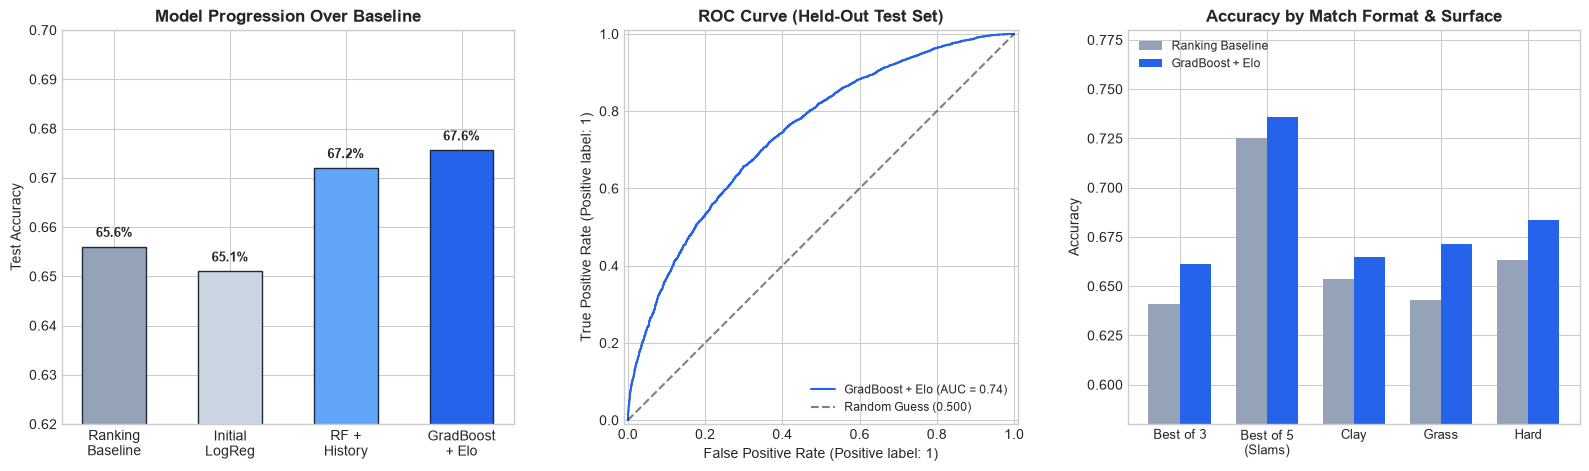

Saved high-resolution chart to figures/model_evaluation_summary.png


In [5]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

os.makedirs('figures', exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# --- Panel 1: Model Progression ---
stages = ['Ranking\nBaseline', 'Initial\nLogReg', 'RF +\nHistory', 'GradBoost\n+ Elo']
accs = [0.656, 0.651, 0.672, test_acc]
colors = ['#94a3b8', '#cbd5e1', '#60a5fa', '#2563eb']

bars = axes[0].bar(stages, accs, color=colors, width=0.55, edgecolor='#1e293b')
axes[0].set_ylim(0.62, 0.70)
axes[0].set_ylabel('Test Accuracy')
axes[0].set_title('Model Progression Over Baseline', fontweight='bold')
for bar, val in zip(bars, accs):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 0.002, f'{val:.1%}', ha='center', fontweight='bold', fontsize=9.5)

# --- Panel 2: ROC Curve ---
RocCurveDisplay.from_predictions(
    y_test, y_prob, ax=axes[1],
    name=f'GradBoost + Elo',
    curve_kwargs={'color': '#2563eb'}
)
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Guess (0.500)')
axes[1].set_title('ROC Curve (Held-Out Test Set)', fontweight='bold')
axes[1].legend(loc='lower right', fontsize=8.5)

# --- Panel 3: Slice Accuracy (Surface & Format) ---
slice_labels = ['Best of 3', 'Best of 5\n(Slams)', 'Clay', 'Grass', 'Hard']
base_vals = [
    format_slice.loc[3, 'Baseline_Acc'],
    format_slice.loc[5, 'Baseline_Acc'],
    surface_slice.loc['Clay', 'Baseline_Acc'],
    surface_slice.loc['Grass', 'Baseline_Acc'],
    surface_slice.loc['Hard', 'Baseline_Acc']
]
mod_vals = [
    format_slice.loc[3, 'Model_Acc'],
    format_slice.loc[5, 'Model_Acc'],
    surface_slice.loc['Clay', 'Model_Acc'],
    surface_slice.loc['Grass', 'Model_Acc'],
    surface_slice.loc['Hard', 'Model_Acc']
]

x = np.arange(len(slice_labels))
w = 0.36
axes[2].bar(x - w/2, base_vals, width=w, label='Ranking Baseline', color='#94a3b8')
axes[2].bar(x + w/2, mod_vals, width=w, label='GradBoost + Elo', color='#2563eb')
axes[2].set_xticks(x)
axes[2].set_xticklabels(slice_labels, fontsize=9)
axes[2].set_ylim(0.58, 0.78)
axes[2].set_ylabel('Accuracy')
axes[2].set_title('Accuracy by Match Format & Surface', fontweight='bold')
axes[2].legend(loc='upper left', fontsize=8.5)

plt.tight_layout()
plt.savefig('figures/model_evaluation_summary.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved high-resolution chart to figures/model_evaluation_summary.png")

In [6]:
# 1. Standalone Model Progression Chart
fig, ax = plt.subplots(figsize=(6.5, 4.5))
bars = ax.bar(stages, accs, color=colors, width=0.5, edgecolor='#1e293b')
ax.set_ylim(0.62, 0.70)
ax.set_ylabel('Test Accuracy')
ax.set_title('Model Progression Over Ranking Baseline', fontweight='bold')
for bar, val in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.002, f'{val:.1%}', ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('figures/01_model_progression.png', dpi=300)
plt.close()

# 2. Standalone ROC Curve (clean single AUC label)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
RocCurveDisplay.from_predictions(
    y_test, y_prob, ax=ax,
    name='GradBoost + Elo',
    curve_kwargs={'color': '#2563eb'}
)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Guess (AUC = 0.50)')
ax.set_title('ROC Curve (Held-Out Test Set)', fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('figures/02_roc_curve.png', dpi=300)
plt.close()

# 3. Standalone Slice Accuracy Chart
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(x - w/2, base_vals, width=w, label='Ranking Baseline', color='#94a3b8')
ax.bar(x + w/2, mod_vals, width=w, label='GradBoost + Elo', color='#2563eb')
ax.set_xticks(x)
ax.set_xticklabels(slice_labels)
ax.set_ylim(0.58, 0.78)
ax.set_ylabel('Accuracy')
ax.set_title('Accuracy by Match Format & Court Surface', fontweight='bold')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('figures/03_slice_accuracy.png', dpi=300)
plt.close()

print("Saved 3 individual slide-ready PNGs to figures/!")

Saved 3 individual slide-ready PNGs to figures/!
